# 04 · Perfiles de clientes (k-means) y red neuronal

**Proyecto:** Alerta temprana de abandono de clientes (Telco Customer Churn)
**Curso:** Machine Learning · Maestría en Ciencia de Datos e Inteligencia Artificial · EPG UNAJ
**Docente:** Dr. Alain Paul Herrera Urtiaga
**Equipo:** Leydy Mayumy Coyllo Mamani · Noe Wilber Tipo Mamani · Jose Alfonso Nina Condori
**Producto:** 2

> **Pregunta del proyecto:** con los datos actuales de un cliente, ¿qué clientes cancelarán su servicio?

**Objetivo de este notebook:** (A) descubrir perfiles de clientes sin usar la etiqueta y ver cuál concentra el abandono; (B) probar una red neuronal y compararla con los mejores modelos.

In [1]:
# Configuración común (el notebook es autocontenido: corre en local y en Google Colab)
import warnings
warnings.filterwarnings("ignore")
import importlib, subprocess, sys
for _paquete in ["lightgbm"]:
    try:
        importlib.import_module(_paquete)
    except ImportError:  # en Colab puede faltar alguna librería
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _paquete], check=True)

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

SEMILLA = 42
URL_CSV = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
RUTA_LOCAL = Path("../data/Telco-Customer-Churn.csv")
EN_REPO = RUTA_LOCAL.exists()
RES = Path("../resultados") if EN_REPO else Path("resultados")
FIG = RES / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

# Paleta: azul = no abandona, naranja = abandona
AZUL, NARANJA, AGUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

def guardar_figura(fig, nombre):
    fig.savefig(FIG / nombre, dpi=150, bbox_inches="tight")

def guardar_json(obj, nombre):
    (RES / nombre).write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding="utf-8")

print("Datos locales:" if EN_REPO else "Datos desde la URL pública:", RUTA_LOCAL if EN_REPO else URL_CSV)

Datos locales: ../data/Telco-Customer-Churn.csv


In [2]:
# Carga y traducción al español (misma lógica que src/churn/datos.py)
MAPEO_COLUMNAS = {
    "customerID": "id_cliente",
    "gender": "genero",
    "SeniorCitizen": "adulto_mayor",
    "Partner": "tiene_pareja",
    "Dependents": "tiene_dependientes",
    "tenure": "antiguedad_meses",
    "PhoneService": "servicio_telefonico",
    "MultipleLines": "lineas_multiples",
    "InternetService": "servicio_internet",
    "OnlineSecurity": "seguridad_en_linea",
    "OnlineBackup": "respaldo_en_linea",
    "DeviceProtection": "proteccion_dispositivo",
    "TechSupport": "soporte_tecnico",
    "StreamingTV": "tv_streaming",
    "StreamingMovies": "peliculas_streaming",
    "Contract": "tipo_contrato",
    "PaperlessBilling": "factura_electronica",
    "PaymentMethod": "metodo_pago",
    "MonthlyCharges": "cargo_mensual",
    "TotalCharges": "cargo_total",
    "Churn": "abandona",
}

MAPEO_VALORES = {
    "Yes": "Sí",
    "No": "No",
    "No internet service": "Sin internet",
    "No phone service": "Sin teléfono",
    "Month-to-month": "Mensual",
    "One year": "Un año",
    "Two year": "Dos años",
    "Fiber optic": "Fibra óptica",
    "DSL": "DSL",
    "Electronic check": "Cheque electrónico",
    "Mailed check": "Cheque por correo",
    "Bank transfer (automatic)": "Transferencia bancaria (automática)",
    "Credit card (automatic)": "Tarjeta de crédito (automática)",
    "Male": "Hombre",
    "Female": "Mujer",
}

OBJETIVO = "abandona"
ID = "id_cliente"
NUMERICAS = ["antiguedad_meses", "cargo_mensual"]
CATEGORICAS = [
    "genero", "adulto_mayor", "tiene_pareja", "tiene_dependientes",
    "servicio_telefonico", "lineas_multiples", "servicio_internet",
    "seguridad_en_linea", "respaldo_en_linea", "proteccion_dispositivo",
    "soporte_tecnico", "tv_streaming", "peliculas_streaming",
    "tipo_contrato", "factura_electronica", "metodo_pago",
]
# cargo_total se excluye del modelo por redundancia (≈ antigüedad × cargo mensual).
# La evidencia está en notebooks/02_modelos.ipynb y en DECISIONES.md.
EXCLUIDAS = [ID, "cargo_total"]
VARIABLES_MODELO = NUMERICAS + CATEGORICAS


def traducir(df: pd.DataFrame) -> pd.DataFrame:
    """Renombra columnas y traduce categorías. Acepta columnas en inglés o ya en español.

    No imputa: los blancos de ``cargo_total`` quedan como NaN.
    """
    df = df.rename(columns=MAPEO_COLUMNAS).copy()
    for col in df.columns:
        if col in (ID, OBJETIVO, "cargo_total") or col in NUMERICAS:
            continue
        if col == "adulto_mayor":
            df[col] = df[col].map(
                lambda v: "Sí" if str(v).strip() in ("1", "1.0", "Sí", "Si", "Yes")
                else ("No" if str(v).strip() in ("0", "0.0", "No") else np.nan)
            )
            continue
        if df[col].dtype == object or pd.api.types.is_string_dtype(df[col]):
            df[col] = df[col].map(lambda v: MAPEO_VALORES.get(v, v) if isinstance(v, str) else v)
            if col == "servicio_internet":  # en esta columna "No" significa "sin internet"
                df[col] = df[col].replace({"No": "Sin internet"})
    if "cargo_total" in df.columns:
        df["cargo_total"] = pd.to_numeric(
            df["cargo_total"].astype(str).str.strip().replace("", np.nan), errors="coerce"
        )
    for col in NUMERICAS:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    if OBJETIVO in df.columns and not pd.api.types.is_numeric_dtype(df[OBJETIVO]):
        df[OBJETIVO] = df[OBJETIVO].map({"Yes": 1, "No": 0, "Sí": 1}).astype(int)
    return df


def separar_X_y(df: pd.DataFrame):
    """Devuelve (X, y) con solo las variables que usa el modelo."""
    return df[VARIABLES_MODELO].copy(), df[OBJETIVO].astype(int).copy()

df_crudo = pd.read_csv(RUTA_LOCAL) if EN_REPO else pd.read_csv(URL_CSV)
df = traducir(df_crudo)
print(df.shape)

(7043, 21)


In [3]:
# Preprocesamiento dentro de un Pipeline (misma lógica que src/churn/preprocesamiento.py)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def construir_preprocesador(numericas=None, categoricas=None) -> ColumnTransformer:
    numericas = list(NUMERICAS if numericas is None else numericas)
    categoricas = list(CATEGORICAS if categoricas is None else categoricas)
    num = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
    ])
    cat = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer(
        [("num", num, numericas), ("cat", cat, categoricas)],
        remainder="drop",
    )


def construir_pipeline(modelo, numericas=None, categoricas=None) -> Pipeline:
    """Pipeline completo: preprocesamiento + modelo."""
    return Pipeline([
        ("prep", construir_preprocesador(numericas, categoricas)),
        ("modelo", modelo),
    ])

In [4]:
# División 80/20 estratificada (la misma semilla en todos los notebooks)
from sklearn.model_selection import train_test_split
X, y = separar_X_y(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
print(f"Entrenamiento: {len(X_train)} filas · Test: {len(X_test)} filas · "
      f"abandono train {y_train.mean():.3f} / test {y_test.mean():.3f}")

Entrenamiento: 5634 filas · Test: 1409 filas · abandono train 0.265 / test 0.265


# Parte A · Perfiles con k-means

Agrupamos a los clientes del **entrenamiento** con las mismas variables del modelo (numéricas escaladas + categóricas en one-hot). **La etiqueta `abandona` no se usa para agrupar**: solo se calcula después, para ver la tasa de abandono de cada perfil.

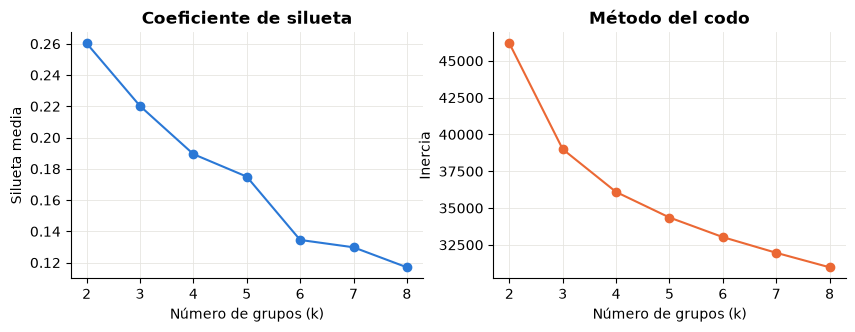

,k,silueta,inercia
0,2,0.2603,46191.7460
1,3,0.2202,38996.6562
2,4,0.1894,36091.2560
3,5,0.1750,34357.0443
4,6,0.1345,33026.2606
5,7,0.1298,31959.9160
6,8,0.1170,30975.4225


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
prep = construir_preprocesador()
Z = prep.fit_transform(X_train)
filas = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z)
    filas.append({"k": k, "silueta": silhouette_score(Z, km.labels_, sample_size=3000, random_state=SEMILLA),
                  "inercia": km.inertia_})
eleccion_k = pd.DataFrame(filas).round(4)
eleccion_k.to_csv(RES / "04_eleccion_k.csv", index=False)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].plot(eleccion_k["k"], eleccion_k["silueta"], "-o", color=AZUL); axs[0].set_title("Coeficiente de silueta")
axs[0].set_xlabel("Número de grupos (k)"); axs[0].set_ylabel("Silueta media")
axs[1].plot(eleccion_k["k"], eleccion_k["inercia"], "-o", color=NARANJA); axs[1].set_title("Método del codo")
axs[1].set_xlabel("Número de grupos (k)"); axs[1].set_ylabel("Inercia")
guardar_figura(fig, "04_eleccion_k.png"); plt.show()
eleccion_k

**Lectura.** La silueta es baja para todos los k (máximo 0.26 con k = 2): los clientes no forman grupos muy separados, algo esperable con datos mayormente categóricos. Con **k = 2** el algoritmo solo separa a los clientes "con internet" de los "sin internet", lo que no aporta nada nuevo. El codo de la inercia está en **k = 3** (la inercia cae 7 195 al pasar de 2 a 3 grupos y solo 2 905 de 3 a 4), que además tiene la segunda mejor silueta (0.22). **Elegimos k = 3** por el codo y por interpretabilidad, y lo dejamos anotado en `DECISIONES.md`.

In [6]:
K = 3
km = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(Z)
perf = X_train.copy(); perf["perfil"] = km.labels_; perf["abandona"] = y_train.values
perfiles = perf.groupby("perfil").agg(
    clientes=("abandona", "size"), tasa_abandono=("abandona", "mean"),
    antiguedad_media=("antiguedad_meses", "mean"), cargo_mensual_medio=("cargo_mensual", "mean"),
    pct_contrato_mensual=("tipo_contrato", lambda s: (s == "Mensual").mean()),
    pct_fibra=("servicio_internet", lambda s: (s == "Fibra óptica").mean()),
    pct_sin_internet=("servicio_internet", lambda s: (s == "Sin internet").mean()),
    pct_cheque_electronico=("metodo_pago", lambda s: (s == "Cheque electrónico").mean()),
    pct_soporte_tecnico=("soporte_tecnico", lambda s: (s == "Sí").mean()),
    pct_peliculas_streaming=("peliculas_streaming", lambda s: (s == "Sí").mean()),
).round(3)
perfiles["pct_del_total"] = (perfiles["clientes"] / len(perf)).round(3)
perfiles

,clientes,tasa_abandono,antiguedad_media,cargo_mensual_medio,pct_contrato_mensual,pct_fibra,pct_sin_internet,pct_cheque_electronico,pct_soporte_tecnico,pct_peliculas_streaming,pct_del_total
perfil,,,,,,,,,,,
0,1214,0.072,30.220,21.115,0.348,0.000,1.0,0.075,0.000,0.000,0.215
1,2414,0.454,14.864,67.691,0.904,0.540,0.0,0.510,0.200,0.307,0.428
2,2006,0.156,55.061,88.124,0.248,0.588,0.0,0.284,0.581,0.729,0.356


**Nombres de los perfiles** (se asignan leyendo la tabla anterior, no la etiqueta):

- **Sin internet (bajo costo):** 100 % sin internet, cargo mensual medio de 21 USD.
- **Nuevos con contrato mensual:** antigüedad media de 15 meses, 90 % con contrato mensual, 51 % paga con cheque electrónico.
- **Leales con muchos servicios:** antigüedad media de 55 meses, cargo medio de 88 USD, 58 % con soporte técnico, 73 % con películas por streaming.

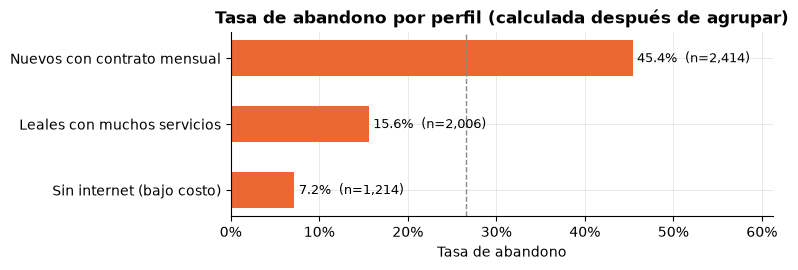

,nombre,clientes,pct_del_total,tasa_abandono
perfil,,,,
0,Sin internet (bajo costo),1214,0.215,0.072
1,Nuevos con contrato mensual,2414,0.428,0.454
2,Leales con muchos servicios,2006,0.356,0.156


In [7]:
NOMBRES = {0: 'Sin internet (bajo costo)', 1: 'Nuevos con contrato mensual', 2: 'Leales con muchos servicios'}
perfiles.insert(0, "nombre", [NOMBRES[i] for i in perfiles.index])
perfiles.to_csv(RES / "04_perfiles.csv")
orden = perfiles.sort_values("tasa_abandono", ascending=False)
fig, ax = plt.subplots(figsize=(7, 0.6 + 0.6 * K))
ax.barh(orden["nombre"][::-1], orden["tasa_abandono"][::-1], color=NARANJA, height=0.55)
ax.axvline(y_train.mean(), color=GRIS, ls="--", lw=1)
for i, (t, n) in enumerate(zip(orden["tasa_abandono"][::-1], orden["clientes"][::-1])):
    ax.text(t + 0.005, i, f"{t:.1%}  (n={n:,})", va="center", fontsize=9)
ax.set_xlim(0, orden["tasa_abandono"].max() * 1.35)
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Tasa de abandono por perfil (calculada después de agrupar)"); ax.set_xlabel("Tasa de abandono")
guardar_figura(fig, "04_abandono_por_perfil.png"); plt.show()
perfiles[["nombre", "clientes", "pct_del_total", "tasa_abandono"]]

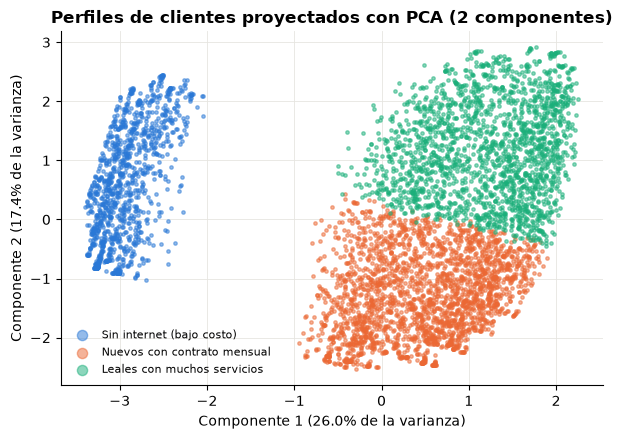

In [8]:
pca = PCA(n_components=2, random_state=SEMILLA)
P = pca.fit_transform(Z)
colores = [AZUL, NARANJA, AGUA, AMARILLO, "#e87ba4", "#008300", "#6250d6", "#e34948"]
fig, ax = plt.subplots(figsize=(7, 4.6))
for i in range(K):
    m = km.labels_ == i
    ax.scatter(P[m, 0], P[m, 1], s=6, alpha=0.5, color=colores[i], label=NOMBRES[i])
ax.set_title("Perfiles de clientes proyectados con PCA (2 componentes)")
ax.set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.1%} de la varianza)")
ax.set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.1%} de la varianza)")
ax.legend(frameon=False, markerscale=3, fontsize=8)
guardar_figura(fig, "04_pca_perfiles.png"); plt.show()
guardar_json({"K": K, "silueta": float(eleccion_k.set_index("k").loc[K, "silueta"]),
              "varianza_pca_2d": round(float(pca.explained_variance_ratio_.sum()), 4)}, "04_kmeans_resumen.json")

**Lectura.** Sin haber usado la etiqueta para agrupar, los perfiles tienen tasas de abandono muy distintas:
- **Nuevos con contrato mensual** (2 414 clientes, 43 % del entrenamiento): **45.4 %** de abandono, 1.7 veces el promedio. **Aquí se concentra el riesgo.**
- **Leales con muchos servicios** (2 006, 36 %): 15.6 %. Pagan más, pero llevan años y tienen servicios de protección.
- **Sin internet (bajo costo)** (1 214, 22 %): 7.2 %.

**Qué haría la empresa:** concentrar el presupuesto de retención en el perfil "nuevos con contrato mensual", con ofertas para pasar a contrato anual, pago automático y soporte técnico en los primeros meses (las mismas palancas que muestran el EDA y el modelo). La proyección PCA (43 % de la varianza en 2 componentes) muestra al grupo "sin internet" claramente separado; los otros dos son contiguos, sin un espacio vacío entre ellos, lo que es coherente con la silueta baja.

# Parte B · Red neuronal (MLP)

Un perceptrón multicapa (`MLPClassifier`, capas ocultas de 32 y 16 neuronas, ReLU, *early stopping*) dentro del **mismo Pipeline**. Como `MLPClassifier` no acepta `class_weight`, el desbalance se trata con **pesos por muestra balanceados** (equivalente). Se compara con los mismos 25 folds (5 × 5) que el notebook 03.

In [9]:
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.utils.class_weight import compute_sample_weight
from scipy.stats import wilcoxon

ruta_opt = RES / "03_optuna_mejores.json"
PARAMS_OPTUNA = json.loads(ruta_opt.read_text())["parametros"] if ruta_opt.exists() else {'n_estimators': 600, 'learning_rate': 0.018928663564375343, 'num_leaves': 32, 'max_depth': 2, 'min_child_samples': 132, 'subsample': 0.630050532322413, 'colsample_bytree': 0.8722648734591396, 'reg_lambda': 4.478210759792659, 'reg_alpha': 0.28373105188382913, 'subsample_freq': 1}
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEMILLA)
METRICAS = {"recall": "recall", "precision": "precision", "roc_auc": "roc_auc", "pr_auc": "average_precision"}
pesos = compute_sample_weight("balanced", y_train)
modelos = {
    "Red neuronal (MLP)": (MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, learning_rate_init=1e-3,
                                         early_stopping=True, max_iter=500, random_state=SEMILLA), True),
    "Regresión logística L2": (LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000), False),
    "LightGBM optimizado": (LGBMClassifier(**PARAMS_OPTUNA, class_weight="balanced", random_state=SEMILLA,
                                           n_jobs=1, verbose=-1), False),
}
folds = {}
for nombre, (modelo, usa_pesos) in modelos.items():
    extra = {"params": {"modelo__sample_weight": pesos}} if usa_pesos else {}
    r = cross_validate(construir_pipeline(modelo), X_train, y_train, cv=cv_rep, scoring=METRICAS, **extra)
    folds[nombre] = {m: r[f"test_{m}"] for m in METRICAS}
resumen = pd.DataFrame({n: {f"{m}_{s}": getattr(v[m], s)() for m in METRICAS for s in ("mean", "std")}
                        for n, v in folds.items()}).T.round(4)
resumen.columns = [c.replace("_mean", "_media").replace("_std", "_desv") for c in resumen.columns]
resumen.index.name = "modelo"
resumen.to_csv(RES / "04_red_vs_modelos.csv")
filas = []
for rival in ["Regresión logística L2", "LightGBM optimizado"]:
    for m in METRICAS:
        a, b = folds["Red neuronal (MLP)"][m], folds[rival][m]
        filas.append({"rival": rival, "metrica": m, "diferencia_media_MLP_menos_rival": (a - b).mean(),
                      "folds_gana_MLP": int((a > b).sum()), "folds_gana_rival": int((a < b).sum()),
                      "p_valor": wilcoxon(a, b).pvalue})
wil_red = pd.DataFrame(filas)
wil_red = wil_red.round({c: 4 for c in wil_red.columns if c != "p_valor"})
wil_red.to_csv(RES / "04_wilcoxon_red.csv", index=False)
display(resumen); wil_red

,recall_media,recall_desv,precision_media,precision_desv,roc_auc_media,roc_auc_desv,pr_auc_media,pr_auc_desv
modelo,,,,,,,,
Red neuronal (MLP),0.7886,0.0335,0.5181,0.0189,0.8381,0.0135,0.6406,0.0198
Regresión logística L2,0.7957,0.0267,0.5209,0.0141,0.8445,0.0111,0.6573,0.0164
LightGBM optimizado,0.8087,0.0281,0.5215,0.0155,0.8500,0.0124,0.6699,0.0186


,rival,metrica,diferencia_media_MLP_menos_rival,folds_gana_MLP,folds_gana_rival,p_valor
0,Regresión logística L2,recall,-0.0071,10,14,9.713167e-02
1,Regresión logística L2,precision,-0.0027,13,12,7.309892e-01
2,Regresión logística L2,roc_auc,-0.0064,5,20,3.194809e-05
3,Regresión logística L2,pr_auc,-0.0167,1,24,1.788139e-07
4,LightGBM optimizado,recall,-0.0201,4,19,1.246181e-03
5,LightGBM optimizado,precision,-0.0033,13,12,7.914760e-01
6,LightGBM optimizado,roc_auc,-0.0118,1,24,4.172325e-07
7,LightGBM optimizado,pr_auc,-0.0293,0,25,5.960464e-08


**Lectura (25 folds).** La red neuronal **no supera a ningún modelo**:
- Frente a la **regresión logística**: recall prácticamente igual (−0.007, 10 folds a 14, p = 0.097, **empate**), pero pierde en ROC-AUC (5 de 25) y en PR-AUC (1 de 25).
- Frente a **LightGBM optimizado**: pierde en recall (−0.020, p = 0.0012), ROC-AUC y PR-AUC.

Con unas 5 600 filas y 18 variables tabulares, la red no tiene ventaja: necesita más datos para aprender interacciones que la regresión logística o el boosting ya capturan, y es más difícil de explicar. **No se adopta.**

## Conclusiones

1. **k-means con k = 3** encuentra tres perfiles interpretables; el de **"nuevos con contrato mensual" concentra el riesgo (45.4 % de abandono)**, frente a 15.6 % y 7.2 % en los otros dos. Es el grupo donde la retención tiene más sentido.
2. Los grupos están poco separados (silueta 0.22): los perfiles sirven para describir y priorizar, no como segmentos rígidos.
3. **La red neuronal (MLP) empata con la regresión logística en recall y pierde con LightGBM optimizado**; no justifica su mayor complejidad en este problema.